# Anime Review Sentiment — Notebook 2: Data Preparation

Turns the raw reviews into a modelling-ready dataset: explores the data, derives the label, cleans the
text, removes show and character names, and engineers features.

**At a glance**
- **16,021 labelled reviews** (80.4% positive / 19.6% negative) after removing duplicates and the neutral 5–6 star band
- One reusable `clean_text()`: POS-aware lemmatisation, stop-words removed but **negations kept**
- **2,427 show/character names stripped by a statistical rule**, checked against an external sentiment lexicon
- 6 style features engineered, **only 2 kept** after a class-separation test

| Input | Output |
|---|---|
| `data/Dataset_A_raw.csv` | `data/Dataset_A_clean.csv` |
| | `data/clean_artifacts.json` — frozen stop-words and name list, so Dataset B and new reviews are cleaned identically |

Dataset B is not touched here.

**Pipeline:** 1. Scraping → **2. Data Preparation** → 3. Modelling & Evaluation

## 1. Setup & load raw Dataset A

NLTK's language data downloads automatically on the first run.

In [1]:
# ============================================================
# Imports & NLTK resource bootstrap
# ============================================================
import os
import re
import time
import collections

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from nltk import pos_tag

for _pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
             "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng",
             "opinion_lexicon"]:
    nltk.download(_pkg, quiet=True)

DATA_DIR = "data"
RAW_A_PATH   = os.path.join(DATA_DIR, "Dataset_A_raw.csv")
CLEAN_A_PATH = os.path.join(DATA_DIR, "Dataset_A_clean.csv")

df = pd.read_csv(RAW_A_PATH)
print(f"Loaded raw Dataset A: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head(3)


Loaded raw Dataset A: 18,738 rows x 6 columns


,anime_id,anime_title,rating,tag,review_date,review_text
0,16498,Shingeki no Kyojin,10,Recommended,"Oct 2, 2014","Oh dear Shingeki no Kyojin, where do I even be..."
1,16498,Shingeki no Kyojin,10,Recommended,"May 7, 2014",I started to follow the manga after watching t...
2,16498,Shingeki no Kyojin,10,Recommended,"Aug 8, 2014","In the 80's, Mobile Suit Gundam catapulted ani..."


In [2]:
# Baseline health check on the raw text before we touch anything
print("Columns:", list(df.columns))
print("\nNulls per column:\n", df.isna().sum())
print("\nRating range:", df["rating"].min(), "to", df["rating"].max())
# duplicates are present by design - the scraper left them in; Step 1a removes them
print("Duplicate (anime_id, review_text) pairs:",
      df.duplicated(subset=["anime_id", "review_text"]).sum())
df["raw_word_count"] = df["review_text"].str.split().str.len()
df["raw_word_count"].describe().round(1)


Columns: ['anime_id', 'anime_title', 'rating', 'tag', 'review_date', 'review_text']

Nulls per column:
 anime_id       0
anime_title    0
rating         0
tag            0
review_date    0
review_text    0
dtype: int64

Rating range: 1 to 10
Duplicate (anime_id, review_text) pairs: 39


count    18738.0
mean       569.4
std        575.0
min         12.0
25%        207.0
50%        394.0
75%        729.0
max      11544.0
Name: raw_word_count, dtype: float64

## 2. Exploring the raw data

Before cleaning anything: what does the corpus look like, and what is the raw text made of? Each finding
below motivates a specific cleaning step later.

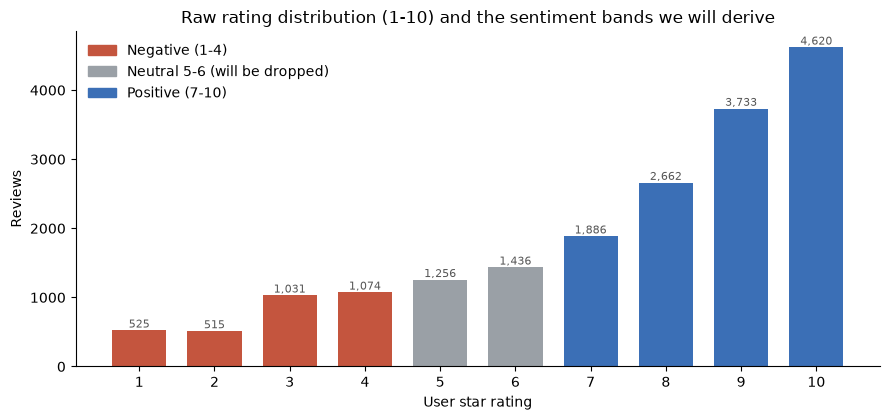

In [3]:
# ============================================================
# EDA 1 — rating distribution (full 1-10 scale, before any dropping)
# ============================================================
NEG_COLOR, NEU_COLOR, POS_COLOR = "#C4553E", "#9AA0A6", "#3B6FB6"
rc = df["rating"].value_counts().reindex(range(1, 11), fill_value=0)
colors = [NEG_COLOR]*4 + [NEU_COLOR]*2 + [POS_COLOR]*4

fig, ax = plt.subplots(figsize=(9, 4.3))
bars = ax.bar(rc.index, rc.values, color=colors, width=0.72)
for b in bars:
    ax.annotate(f"{int(b.get_height()):,}", (b.get_x()+b.get_width()/2, b.get_height()),
                ha="center", va="bottom", fontsize=8, color="#555")
ax.set_xticks(range(1, 11)); ax.set_xlabel("User star rating"); ax.set_ylabel("Reviews")
ax.set_title("Raw rating distribution (1-10) and the sentiment bands we will derive")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(handles=[plt.Rectangle((0,0),1,1,color=c) for c in (NEG_COLOR, NEU_COLOR, POS_COLOR)],
          labels=["Negative (1-4)", "Neutral 5-6 (will be dropped)", "Positive (7-10)"],
          frameon=False, loc="upper left")
plt.tight_layout(); plt.show()


**Insight.** Ratings skew heavily towards 7–10, previewing the ~80/20 class imbalance. The grey 5–6 band
that will be dropped is a sizeable slice, not a rounding detail.

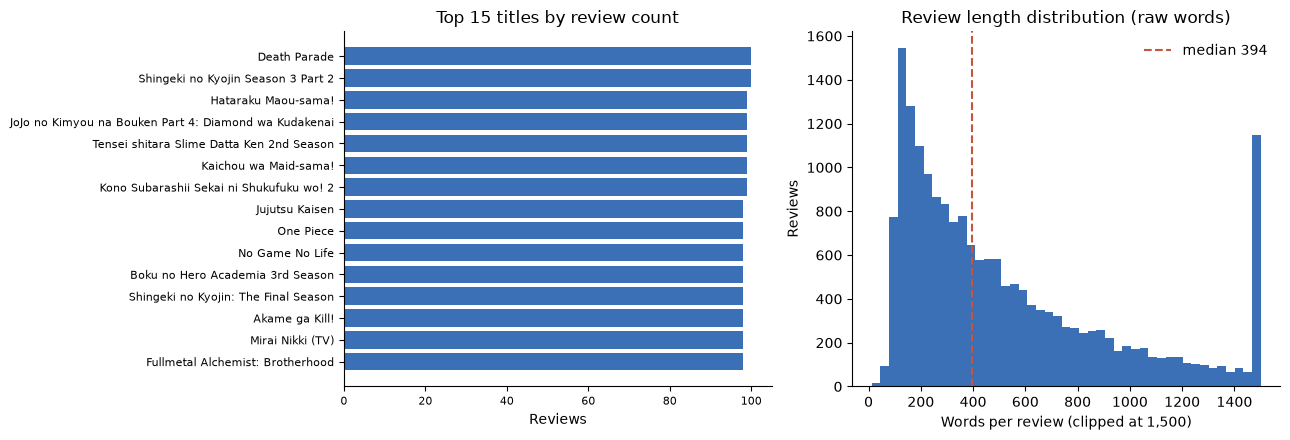

Reviews span 200 titles | median length 394 words, longest 11,544 words


In [4]:
# ============================================================
# EDA 2 — reviews per title & review-length distribution
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

top_titles = df["anime_title"].value_counts().head(15).sort_values()
axes[0].barh(top_titles.index, top_titles.values, color="#3B6FB6")
axes[0].set_title("Top 15 titles by review count"); axes[0].set_xlabel("Reviews")
axes[0].tick_params(labelsize=8); axes[0].spines[["top", "right"]].set_visible(False)

axes[1].hist(df["raw_word_count"].clip(upper=1500), bins=45, color="#3B6FB6")
axes[1].set_title("Review length distribution (raw words)")
axes[1].set_xlabel("Words per review (clipped at 1,500)"); axes[1].set_ylabel("Reviews")
axes[1].axvline(df["raw_word_count"].median(), color="#C4553E", ls="--",
                label=f"median {df['raw_word_count'].median():.0f}")
axes[1].legend(frameon=False); axes[1].spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

print(f"Reviews span {df['anime_title'].nunique()} titles | "
      f"median length {df['raw_word_count'].median():.0f} words, "
      f"longest {df['raw_word_count'].max():,} words")


**Insight.** Coverage is even across ~200 titles, so no show dominates, and reviews are long-form prose
(median ~400 words).

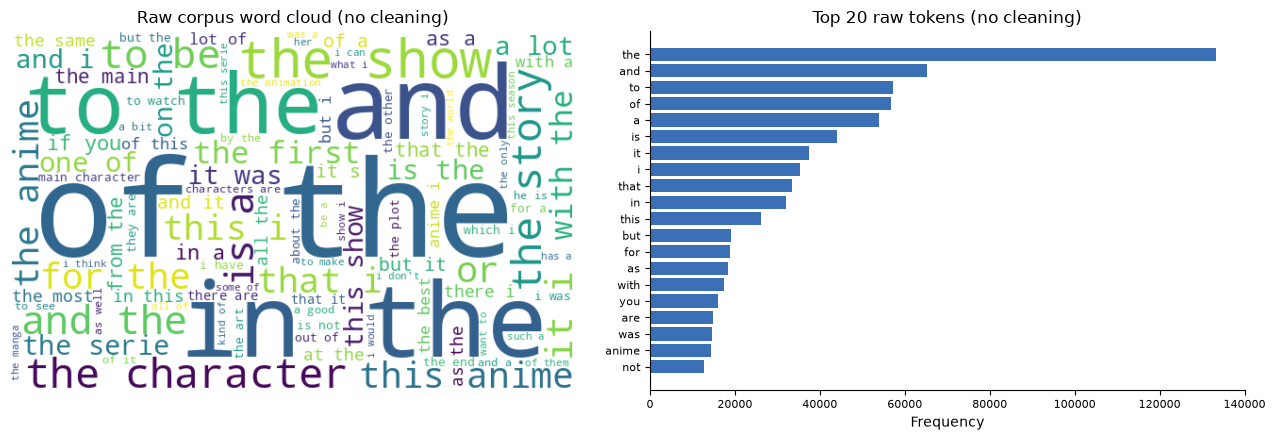

In [5]:
# ============================================================
# EDA 3 — what words dominate the RAW corpus? (nothing cleaned yet)
# ============================================================
from wordcloud import WordCloud

# take a sample for speed; raw text, NO stop-word removal -> shows filler dominates
raw_blob = " ".join(df["review_text"].dropna().sample(4000, random_state=1).astype(str)).lower()
raw_tokens = re.findall(r"[a-z']+", raw_blob)
top_raw = collections.Counter(raw_tokens).most_common(20)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
wc_raw = WordCloud(width=600, height=380, background_color="white",
                   stopwords=set(), colormap="viridis", max_words=100).generate(raw_blob)
axes[0].imshow(wc_raw, interpolation="bilinear"); axes[0].axis("off")
axes[0].set_title("Raw corpus word cloud (no cleaning)")

words, counts = zip(*top_raw)
axes[1].barh(list(words)[::-1], list(counts)[::-1], color="#3B6FB6")
axes[1].set_title("Top 20 raw tokens (no cleaning)"); axes[1].set_xlabel("Frequency")
axes[1].tick_params(labelsize=8); axes[1].spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()


**Insight → why we clean.** The most frequent raw tokens are *the, and, to, of, is* plus filler like
*anime*. They carry no sentiment and would swamp a bag-of-words model.

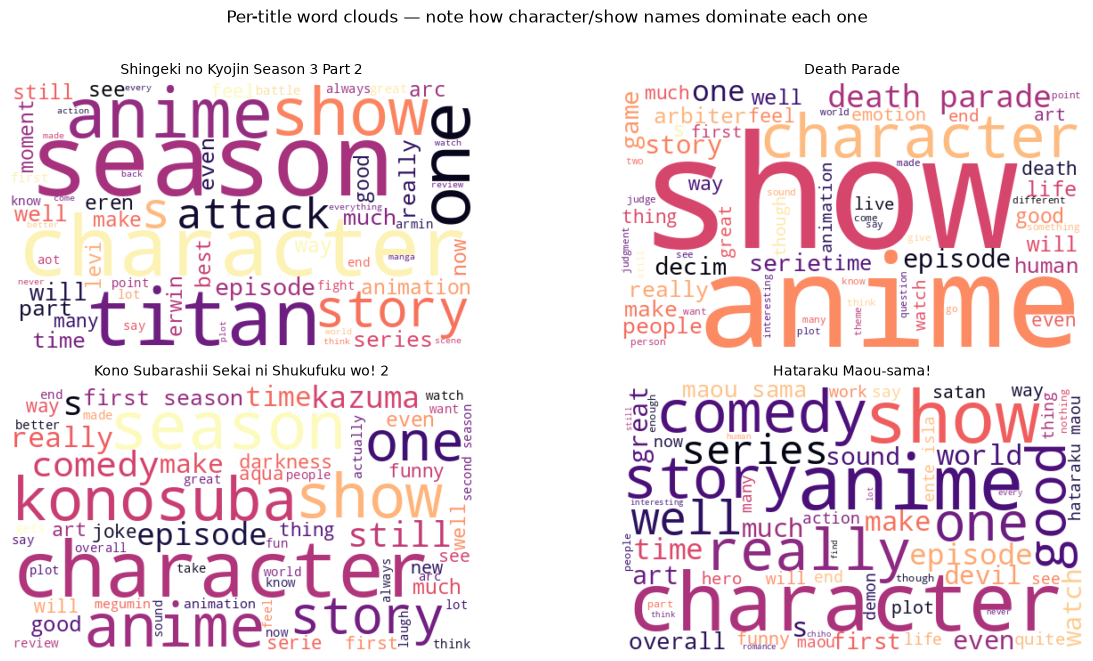

In [6]:
# ============================================================
# EDA 4 — per-title word clouds: vocabulary is show-specific
# ============================================================
top4 = df["anime_title"].value_counts().head(4).index.tolist()
fig, axes = plt.subplots(2, 2, figsize=(13, 6.5))
for ax, title in zip(axes.ravel(), top4):
    blob = " ".join(df.loc[df.anime_title == title, "review_text"].astype(str)).lower()
    # default WordCloud stop-words ON here, so content words (incl. names) show through
    wc = WordCloud(width=520, height=300, background_color="white",
                   colormap="magma", max_words=60).generate(blob)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off")
    ax.set_title(title, fontsize=10)
plt.suptitle("Per-title word clouds — note how character/show names dominate each one", y=1.01)
plt.tight_layout(); plt.show()


**Insight → why we strip names.** Each show's cloud is dominated by its own character and title names
(*eren, titan, mikasa*). Because popular shows are well liked, a model could learn "this name → positive"
and then fail on shows it has never seen. This is the evidence behind Step 6.

## 3. Step 1 — Build the labelled record set

**1a. Remove duplicates.** A duplicate adds nothing new, and one copy could land in training and the other
in validation, inflating the score. The key is `(anime_id, review_text)`: identical text on the *same*
title is a pagination artifact, while identical text on different titles may be genuine cross-posting and
is kept.

In [7]:
# ============================================================
# Step 1a — remove duplicate reviews
# ============================================================
n_before = len(df)
df = df.drop_duplicates(subset=["anime_id", "review_text"]).reset_index(drop=True)
n_dupes = n_before - len(df)
print(f"Duplicate rows removed: {n_dupes:,} ({n_dupes/n_before*100:.2f}% of the raw input)")
print(f"Unique reviews remaining: {len(df):,}")

# confirm the operation actually worked
assert df.duplicated(subset=["anime_id", "review_text"]).sum() == 0
print("Verified: zero duplicate (anime_id, review_text) pairs remain")


Duplicate rows removed: 39 (0.21% of the raw input)
Unique reviews remaining: 18,699
Verified: zero duplicate (anime_id, review_text) pairs remain


**1b. Derive the label.** 7–10 → 1, 1–4 → 0, and **5–6 are dropped**. Mid-range reviews routinely praise
one thing and condemn another in the same paragraph, so they blur the boundary between the classes.
Dropping them gives a cleaner separation for a linear model to learn.

In [8]:
# ============================================================
# Step 1b — map rating -> binary sentiment, drop the neutral band
# ============================================================
def derive_sentiment(rating):
    """7-10 -> 1 (positive), 1-4 -> 0 (negative), 5-6 -> NaN (drop)."""
    if rating >= 7:
        return 1
    if rating <= 4:
        return 0
    return np.nan

df["sentiment"] = df["rating"].apply(derive_sentiment)

n_before = len(df)
df = df.dropna(subset=["sentiment"]).copy()
df["sentiment"] = df["sentiment"].astype(int)
print(f"Dropped {n_before - len(df):,} neutral (5-6 star) reviews")
print(f"Remaining labelled reviews: {len(df):,}\n")

dist = df["sentiment"].value_counts().sort_index()
print("Class distribution:")
print(f"  Negative (0): {dist[0]:,}  ({dist[0]/len(df)*100:.1f}%)")
print(f"  Positive (1): {dist[1]:,}  ({dist[1]/len(df)*100:.1f}%)")


Dropped 2,678 neutral (5-6 star) reviews
Remaining labelled reviews: 16,021

Class distribution:
  Negative (0): 3,142  (19.6%)
  Positive (1): 12,879  (80.4%)


**Insight.** About 80% positive / 20% negative. This shapes notebook 3: report **per-class
precision/recall and macro-F1** rather than accuracy, **stratify** every split, and use **class weights**.

## 4. Step 2 — Measure the noise before cleaning it

Rather than applying a textbook recipe blindly, this scan measures which noise patterns actually occur in
this corpus.

In [9]:
# ============================================================
# Step 2 — quantify noise patterns in OUR corpus
# ============================================================
col = df["review_text"].fillna("")
def prevalence(pattern):
    return col.str.contains(pattern, regex=True).mean() * 100

patterns = {
    "HTML tags  <...>"          : r"<[^>]+>",
    "HTML entities  &..;"       : r"&[a-z]+;",
    "URLs  http..."             : r"http\S+",
    "'read more' ellipsis  ..." : r"\.\.\.",
    "digits"                    : r"\d",
    "non-ASCII chars"           : r"[^\x00-\x7F]",
}
print("Noise pattern prevalence (share of reviews containing it):")
for name, pat in patterns.items():
    print(f"  {name:28s} {prevalence(pat):5.1f}%")


Noise pattern prevalence (share of reviews containing it):
  HTML tags  <...>               0.2%
  HTML entities  &..;            1.7%
  URLs  http...                  0.6%
  'read more' ellipsis  ...     96.9%


  digits                        78.1%
  non-ASCII chars               22.5%


**Reading the scan.** HTML and URLs are rare but must not become tokens. Digits (episode counts, years)
are everywhere and carry no sentiment. The `...` in ~97% of reviews is MAL's "read more" join plus stylistic
ellipses, and is normalised away. Non-ASCII is mostly smart quotes and Japanese terms.

## 5. Step 3 — Stop-word set

NLTK's English list, adjusted in two directions:
- **Negations taken out of the list, so they survive:** *not, no, never, don't…* Deleting *never* from
  "never bad" would flip its meaning.
- **Domain filler added:** *anime, episode, season, watch, series…* appear in every review regardless of rating.

*Story, plot* and *character* are just as common but are **kept**, because they carry sentiment inside
phrases ("bad plot" vs "brilliant plot"), and notebook 3's bigrams turn those phrases into features. The
test was "can this word be part of a sentiment phrase?", not "is it frequent?".

In [10]:
# ============================================================
# Step 3 — stop-word set: English base + domain, minus negations
# ============================================================
base_stop = set(stopwords.words("english"))

# keep negation words - they flip sentiment and must survive cleaning
NEGATIONS = {"no", "not", "nor", "never", "none", "cannot",
             "don", "didn", "doesn", "isn", "wasn", "aren", "won", "wouldn",
             "couldn", "shouldn", "hasn", "haven", "hadn"}
base_stop -= NEGATIONS

# domain words: ubiquitous across all ratings -> non-discriminative for sentiment
DOMAIN_STOP = {"anime", "manga", "episode", "episodes", "ep", "eps", "series",
               "season", "seasons", "show", "watch", "watching", "watched",
               "review", "reviews", "mal", "myanimelist", "oav", "ova", "arc"}

STOPWORDS = base_stop | DOMAIN_STOP
print(f"English stop-words (minus negations): {len(base_stop)}")
print(f"+ domain stop-words: {len(DOMAIN_STOP)}")
print(f"= total stop-word set: {len(STOPWORDS)}")
print("\nNegations deliberately KEPT:", sorted(NEGATIONS)[:8], "...")


English stop-words (minus negations): 182
+ domain stop-words: 20
= total stop-word set: 202

Negations deliberately KEPT: ['aren', 'cannot', 'couldn', 'didn', 'doesn', 'don', 'hadn', 'hasn'] ...


## 6. Step 4 — The core cleaning function

`clean_text()`: lowercase → strip HTML, entities and URLs → collapse repeated punctuation → drop digits and
punctuation → tokenise → **POS-tag, then lemmatise** → remove stop-words and tokens of ≤ 2 characters.

The POS tag comes first because WordNet needs the part of speech to lemmatise correctly: with a tag,
*better* becomes *well*; without one it is treated as a noun and left unchanged. Name removal is a separate
step (Step 6), because it needs statistics over the whole corpus.

In [11]:
# ============================================================
# Step 4 — the reusable core cleaning pipeline
# ============================================================
lemmatizer = WordNetLemmatizer()

HTML_TAG_RE  = re.compile(r"<[^>]+>")
HTML_ENT_RE  = re.compile(r"&[a-z]+;")
URL_RE       = re.compile(r"http\S+|www\.\S+")
REPEAT_PUNC  = re.compile(r"([!?.])\1+")          # !!!! -> !, .... -> .
NON_ALPHA_RE = re.compile(r"[^a-z\s]")            # keep letters + spaces only
MULTISPACE   = re.compile(r"\s+")

def _wordnet_pos(treebank_tag):
    """Map a Penn-Treebank POS tag to the WordNet POS the lemmatiser expects."""
    if treebank_tag.startswith("J"):
        return wordnet.ADJ
    if treebank_tag.startswith("V"):
        return wordnet.VERB
    if treebank_tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

def clean_text(text):
    """Character cleanup -> tokenise -> POS-aware lemmatise -> stop-word removal.
    Returns a list of lemmatised tokens (entity removal happens later)."""
    if not isinstance(text, str):
        return []
    text = text.lower()
    text = HTML_TAG_RE.sub(" ", text)
    text = HTML_ENT_RE.sub(" ", text)
    text = URL_RE.sub(" ", text)
    text = REPEAT_PUNC.sub(r"\1", text)
    text = NON_ALPHA_RE.sub(" ", text)
    text = MULTISPACE.sub(" ", text).strip()

    tokens = word_tokenize(text)
    cleaned = []
    for tok, tag in pos_tag(tokens):
        if len(tok) <= 2 or tok in STOPWORDS:
            continue
        lemma = lemmatizer.lemmatize(tok, _wordnet_pos(tag))
        if len(lemma) <= 2 or lemma in STOPWORDS:
            continue
        cleaned.append(lemma)
    return cleaned

# demonstrate on one real review so the transformation is visible
_demo = df["review_text"].iloc[0]
print("RAW  :", _demo[:220], "...\n")
print("CLEAN:", " ".join(clean_text(_demo))[:220], "...")


RAW  : Oh dear Shingeki no Kyojin, where do I even begin. If you've talked with your friends about anime, then the couple anime that everyone talks about are Naruto, Bleach, One Piece, Dragon Ball, and... Shingeki no Kyojin. Wh ...



CLEAN: dear shingeki kyojin even begin talk friend couple everyone talk naruto bleach one piece dragon ball shingeki kyojin difference shingeki rest shingeki far yet par popularity super long americanized popular well simply st ...


### Step 4b — Stemming or lemmatisation?

Both reduce words to a base form, so the choice is tested directly on this data:

In [12]:
# ============================================================
# Step 4b - stemming vs lemmatisation, compared on our own data
# ============================================================
from nltk.stem import PorterStemmer
stemmer = PorterStemmer()

# 1. side by side on words that actually matter for sentiment
words = ["running", "better", "studies", "animation", "beautiful", "watched",
         "amazing", "disappointing", "boring", "masterpiece", "worse", "easily"]
comparison = pd.DataFrame({
    "original":   words,
    "stemmed":    [stemmer.stem(w) for w in words],
    "lemmatised": [lemmatizer.lemmatize(w, _wordnet_pos(pos_tag([w])[0][1])) for w in words],
})
print("Word-level comparison:")
display(comparison)

# 2. effect on vocabulary size, measured on a sample of real reviews
sample = df["review_text"].dropna().astype(str).head(500)
stem_vocab, lemma_vocab = set(), set()
for text in sample:
    toks = word_tokenize(MULTISPACE.sub(" ", NON_ALPHA_RE.sub(" ", text.lower())).strip())
    toks = [t for t in toks if len(t) > 2 and t not in STOPWORDS]
    stem_vocab.update(stemmer.stem(t) for t in toks)
    for tok, tag in pos_tag(toks):
        lemma_vocab.update([lemmatizer.lemmatize(tok, _wordnet_pos(tag))])

print(f"\nOn {len(sample)} reviews:")
print(f"  vocabulary after STEMMING      : {len(stem_vocab):,}")
print(f"  vocabulary after LEMMATISATION : {len(lemma_vocab):,}")
print(f"  stemming is {(1-len(stem_vocab)/len(lemma_vocab))*100:.1f}% more aggressive")

# 3. how a real sentence comes out under each
demo = "The animation was beautiful but the story felt rushed and it was easily the worst episode"
demo_toks = word_tokenize(demo.lower())
print(f"\noriginal   : {demo}")
print("stemmed    :", " ".join(stemmer.stem(t) for t in demo_toks))
print("lemmatised :", " ".join(lemmatizer.lemmatize(t, _wordnet_pos(g))
                               for t, g in pos_tag(demo_toks)))


Word-level comparison:


,original,stemmed,lemmatised
0,running,run,run
1,better,better,well
2,studies,studi,study
3,animation,anim,animation
4,beautiful,beauti,beautiful
5,watched,watch,watch
6,amazing,amaz,amaze
7,disappointing,disappoint,disappoint
8,boring,bore,boring
9,masterpiece,masterpiec,masterpiece



On 500 reviews:
  vocabulary after STEMMING      : 9,437
  vocabulary after LEMMATISATION : 11,753
  stemming is 19.7% more aggressive

original   : The animation was beautiful but the story felt rushed and it was easily the worst episode
stemmed    : the anim wa beauti but the stori felt rush and it wa easili the worst episod
lemmatised : the animation be beautiful but the story felt rush and it be easily the bad episode


**Decision: lemmatisation.**
1. **Readable output.** Stemming produces fragments (*anim, beauti, studi*). Notebook 3 uses the model's
   top-weighted words as evidence that it learned sentiment rather than names, which only works if a person
   can read them.
2. **Irregular forms.** Lemmatisation maps *worse* and *worst* to *bad*; stemming gives *wors* and leaves
   *better* unchanged. Comparatives and superlatives carry much of the sentiment in reviews.

*Trade-off:* stemming shrinks the vocabulary further, but with ~16,000 reviews vocabulary size is not the
bottleneck, while interpretability is something the project needs.

## 7. Step 5 — Clean every review

The expensive POS-tag + lemmatise pass runs once; name removal is applied on top of the stored tokens.

In [13]:
# ============================================================
# Step 5 — clean all reviews (core pass)
# ============================================================
t0 = time.time()
df["base_tokens"] = df["review_text"].apply(clean_text)
print(f"Cleaned {len(df):,} reviews in {time.time()-t0:.0f}s")
print("Mean tokens/review after core clean:", round(df['base_tokens'].apply(len).mean(), 1))


Cleaned 16,021 reviews in 151s
Mean tokens/review after core clean: 265.7


## 8. Step 6 — Remove show and character names (the context-blindness step)

The model will be used on **new** anime, where existing character names never appear. Worse, because
popular shows are well liked, names act as shortcuts to "positive". Removing them forces the model to learn
sentiment language that transfers.

**The rule needs no hand-made name list.** Count how many distinct titles each word appears in. Names are
confined to their show and its sequels, while words like *good, boring, masterpiece* are used across almost
every show. A word is removed if it is **frequent (≥ 30 uses) but appears in ≤ 15% of titles** (30 of 200).

*Why 30 shows and not 2?* An earlier cut-off of 2 caught almost nothing: sequels count as separate titles,
so a character like *nakiri* appears in four "different" shows.

**Checking the cut-off is safe** against an external list, the Hu & Liu (2004) opinion lexicon of ~6,800
sentiment words. Using a list not written for this project keeps the check honest:
- Real sentiment words sit well above the cut-off. The lowest, *insulting*, appears in 34 shows; *boring,
  waste, masterpiece* appear in 195–200.
- The ~280 lexicon words that do fall below it turn out to be **title and plot words** (*slime, darling,
  dungeon* from titles; *apocalypse, terrorism* from plots), so removing them helps the goal.
- *Rejected alternative:* protecting the whole lexicon from removal would have kept those title words. The
  lexicon is therefore used to **verify** the threshold, not to override it.

In [14]:
# ============================================================
# Step 6a - detect show-specific entity tokens by cross-show frequency
# ============================================================
N_SHOWS = df["anime_title"].nunique()

# for every token: total frequency + how many DISTINCT shows it appears in
token_freq      = collections.Counter()
token_showcount = collections.defaultdict(set)
for title, toks in zip(df["anime_title"], df["base_tokens"]):
    token_freq.update(toks)
    for t in set(toks):
        token_showcount[t].add(title)

def n_shows(tok):
    return len(token_showcount.get(tok, ()))

# ---- the rule -------------------------------------------------------------
FREQ_MIN  = 30   # said often enough to actually influence the model

# The show-count cut-off is expressed as a PROPORTION of the catalogue rather than a
# fixed number. "Appears in at most 15% of the titles" is a well-defined idea at any
# corpus size; a bare "30" only means the same thing while there happen to be 200
# titles. If the notebook is re-run with fewer titles (see the runtime note in
# notebook 1), a fixed 30 would start deleting ordinary vocabulary: at 100 titles it
# would strip 21% of the sentiment lexicon instead of 11%, and at 50 titles 39%.
# At the current 200 titles this evaluates to 30, so nothing about the results changes.
SHOWS_MAX = max(2, round(N_SHOWS * 0.15))

ENTITY_TOKENS = {t for t, f in token_freq.items()
                 if f >= FREQ_MIN and n_shows(t) <= SHOWS_MAX}

lost_mass  = sum(token_freq[t] for t in ENTITY_TOKENS)
total_mass = sum(token_freq.values())

print(f"Vocabulary size (core clean): {len(token_freq):,}")
print(f"Rule: strip if freq >= {FREQ_MIN} and appears in <= {SHOWS_MAX} of {N_SHOWS} shows")
print(f"Entity tokens detected: {len(ENTITY_TOKENS):,}")
print(f"Token occurrences removed: {lost_mass:,} of {total_mass:,} "
      f"({lost_mass/total_mass*100:.2f}%)")
print(f"Examples: {sorted(ENTITY_TOKENS, key=lambda t: -token_freq[t])[:15]}")


Vocabulary size (core clean): 57,678
Rule: strip if freq >= 30 and appears in <= 30 of 200 shows
Entity tokens detected: 2,327
Token occurrences removed: 192,643 of 4,256,049 (4.53%)
Examples: ['subaru', 'goblin', 'kaguya', 'eren', 'haikyuu', 'yato', 'saitama', 'hachiman', 'dio', 'satoru', 'shinkai', 'konosuba', 'noragami', 'spy', 'hyouka']


In [15]:
# ============================================================
# Step 6b - verify the threshold against an EXTERNAL sentiment word list
# ============================================================
# The Hu & Liu (2004) opinion lexicon bundled with NLTK: ~6,800 sentiment words.
# It is used to CHECK the threshold, not to override it - see the markdown above.
from nltk.corpus import opinion_lexicon
LEXICON = set(opinion_lexicon.positive()) | set(opinion_lexicon.negative())

def profile(tok):
    return token_freq.get(tok, 0), n_shows(tok)

# ---- 1. do the names actually get stripped? -------------------------------
REF_NAMES = ["thorfinn", "rudeus", "senku", "denji", "yuta", "nakiri", "totsuki",
             "aisaka", "oikawa", "yuuko", "touji", "eren", "mikasa", "gojo", "saitama",
             "miyazaki", "mappa", "hisaishi", "subaru", "kaneki"]
REF_NAMES = [w for w in REF_NAMES if token_freq.get(w, 0) > 0]

print("REFERENCE NAMES (want: stripped)")
print(f"  {'token':14s} {'freq':>6s} {'#shows':>7s}  stripped?")
caught = 0
for w in REF_NAMES:
    f, s = profile(w)
    hit = w in ENTITY_TOKENS
    caught += hit
    print(f"  {w:14s} {f:>6d} {s:>7d}  {'YES' if hit else 'no  <-- survived'}")
print(f"  -> {caught} of {len(REF_NAMES)} stripped")

# ---- 2. is the threshold safe for real sentiment vocabulary? --------------
# Every sentiment word that does real work in this corpus should sit ABOVE the
# cut-off, which is what makes a threshold of 30 safe.
print("\nSENTIMENT VOCABULARY (want: kept, i.e. #shows > SHOWS_MAX)")
print(f"  {'token':14s} {'freq':>6s} {'#shows':>7s}  kept?")
for w in ["insulting", "incoherent", "soulless", "unfunny", "abysmal", "atrocious",
          "laughably", "horrendous", "pathetic", "mediocre", "generic", "waste",
          "boring", "masterpiece", "amazing", "beautiful"]:
    f, s = profile(w)
    if f:
        print(f"  {w:14s} {f:>6d} {s:>7d}  "
              f"{'STRIPPED <-- would be a problem' if w in ENTITY_TOKENS else 'kept'}")

lex_in_corpus = {w for w in LEXICON if token_freq.get(w, 0) >= FREQ_MIN}
lex_removed   = sorted((w for w in lex_in_corpus if w in ENTITY_TOKENS),
                       key=lambda w: -token_freq[w])
print(f"\nLexicon words present in corpus: {len(lex_in_corpus):,}")
print(f"Lexicon words removed by the rule: {len(lex_removed)} "
      f"({len(lex_removed)/len(lex_in_corpus)*100:.1f}%)")
print(f"  what they are: {lex_removed[:15]}")
print("  -> inspected manually: these are title and plot words (Slime, Darling,")
print("     Dungeon, Parasyte, Promised Neverland; apocalypse, racism, terrorism),")
print("     not sentiment words. Removing them serves the context-blindness goal.")

# ---- 3. the strip-set really is the rule alone ----------------------------
rule_only = {t for t, f in token_freq.items()
             if f >= FREQ_MIN and n_shows(t) <= SHOWS_MAX}
assert rule_only == ENTITY_TOKENS
print("\nVerified: the strip-set is produced by the statistical rule alone.")
print("The reference names and the lexicon are only used to check it.")


REFERENCE NAMES (want: stripped)
  token            freq  #shows  stripped?
  thorfinn          257       1  YES
  rudeus            518       2  YES
  senku             279       2  YES
  denji             171       2  YES
  yuta              144       3  YES
  nakiri             52       4  YES
  totsuki            48       3  YES
  aisaka             44       3  YES
  oikawa             55       4  YES
  yuuko              54       4  YES
  touji              58       3  YES
  eren              906      27  YES
  mikasa            278      12  YES
  gojo              331       7  YES
  saitama           609      23  YES
  miyazaki          475      30  YES
  mappa             455      19  YES
  hisaishi           46       5  YES
  subaru           1358      12  YES
  kaneki            506       9  YES
  -> 20 of 20 stripped

SENTIMENT VOCABULARY (want: kept, i.e. #shows > SHOWS_MAX)
  token            freq  #shows  kept?
  insulting          40      34  kept
  incoherent         60 

**Result.** All 20 reference names are stripped, including widely name-dropped ones like *eren* (27 shows),
every sentiment word in the spot-check is kept, and the assertion confirms the strip-set comes from the rule
alone. *Limitation:* the reference names are hand-picked, since no public list of anime character names
exists; the stronger evidence is the external lexicon. The real test is notebook 3's score on unseen Dataset B.

### Title words need two tests, not one

| Attempt | Rule | Problem |
|---|---|---|
| 1 | Strip every word that appears in a show title | Deleted ordinary words: *story* (Clannad: After **Story**), *art* (Sword **Art** Online), *animation* |
| 2 | Strip title words only if they fail the cross-show test | Let famous names back in, because reviewers of other shows name-drop them ("better than Shingeki") |

**Final rule:** strip a title word if it is **not an English word** (checked against WordNet) **or** it is
confined to few shows. *Shingeki* and *naruto* go; *story, art* and *animation* stay. *Known leak:*
*jujutsu* and *academia* are in WordNet and survive — a small cost compared with deleting *story* everywhere.

In [16]:
# ============================================================
# Step 6c - apply the entity filter and build the final cleaned text
# ============================================================
# Title words need TWO tests, because neither alone is sufficient:
#   * a pure cross-show test lets famous franchise names through, since reviewers of
#     other shows name-drop them ("better than Shingeki", "not another Naruto")
#   * stripping every title word unconditionally deletes ordinary vocabulary, which is
#     how "story" (Clannad: After Story), "art" (Sword Art Online) and "animation"
#     (Danganronpa ... The Animation) were wrongly removed in an earlier version
# A title word is therefore stripped if it is NOT an English dictionary word, OR if it
# is English but still confined to few shows.
title_tokens = set()
for title in df["anime_title"].dropna().unique():
    title_tokens.update(re.findall(r"[a-z]{3,}", title.lower()))

def is_english(word):
    """True if WordNet knows the word, i.e. it is ordinary English rather than romaji."""
    return bool(wordnet.synsets(word))

title_specific = {t for t in title_tokens
                  if (not is_english(t)) or n_shows(t) <= SHOWS_MAX}
title_general  = title_tokens - title_specific

STRIP_SET = ENTITY_TOKENS | title_specific

print(f"Title words found: {len(title_tokens)}")
print(f"  stripped (romaji, or English but show-specific): {len(title_specific)}")
print(f"  kept (English and used across many shows)      : {len(title_general)}")
print(f"\nFinal strip-set: {len(STRIP_SET)} tokens "
      f"({len(ENTITY_TOKENS)} statistical + {len(title_specific - ENTITY_TOKENS)} title-only)")

df["clean_tokens"] = df["base_tokens"].apply(
    lambda toks: [t for t in toks if t not in STRIP_SET])
df["clean_text"] = df["clean_tokens"].apply(" ".join)

# ---- verify BOTH directions of the rule -----------------------------------
print("\nromaji title words (want: stripped)")
for w in ["shingeki", "kyojin", "naruto", "kimetsu", "yaiba", "clannad", "evangelion"]:
    if w in title_tokens:
        print(f"  {w:<12} stripped: {w in STRIP_SET}")
print("\nreview vocabulary needed for the aspect analysis (want: kept)")
for w in ["story", "art", "animation", "plot", "character", "pacing", "music"]:
    print(f"  {w:<12} kept: {w not in STRIP_SET}  (appears in {n_shows(w)} shows)")

print("\nBEFORE entity strip:", " ".join(df['base_tokens'].iloc[0])[:170], "...")
print("\nAFTER  entity strip:", df['clean_text'].iloc[0][:170], "...")


Title words found: 353
  stripped (romaji, or English but show-specific): 257
  kept (English and used across many shows)      : 96

Final strip-set: 2427 tokens (2327 statistical + 100 title-only)



romaji title words (want: stripped)
  shingeki     stripped: True
  kyojin       stripped: True
  naruto       stripped: True
  kimetsu      stripped: True
  yaiba        stripped: True
  clannad      stripped: True
  evangelion   stripped: True

review vocabulary needed for the aspect analysis (want: kept)
  story        kept: True  (appears in 200 shows)
  art          kept: True  (appears in 200 shows)
  animation    kept: True  (appears in 200 shows)
  plot         kept: True  (appears in 200 shows)
  character    kept: True  (appears in 200 shows)
  pacing       kept: True  (appears in 198 shows)
  music        kept: True  (appears in 200 shows)

BEFORE entity strip: dear shingeki kyojin even begin talk friend couple everyone talk naruto bleach one piece dragon ball shingeki kyojin difference shingeki rest shingeki far yet par popular ...

AFTER  entity strip: dear even begin talk friend couple everyone talk bleach one piece dragon ball difference rest far yet par popularity supe

## 9. Step 7 — Style features

TF-IDF records *which* words appear, not *how* the review was written. Six candidate features capture style:
exclamation and question counts, ALL-CAPS words, uppercase ratio, punctuation density and average word
length. They are computed from the **raw** text, because cleaning removes exactly the capitals and
punctuation they measure.

*Deliberately not built:* an ellipsis count. MAL inserts `...` at every "read more" break, so it would
measure a scraping artifact rather than writing style.

In [17]:
# ============================================================
# Step 7a — stylistic meta-features (computed from RAW text)
# ============================================================
import string as _string

def meta_features(text):
    """Extract style signals from the ORIGINAL (uncleaned) review text.
    (Ellipsis count is intentionally NOT computed - see markdown above.)"""
    if not isinstance(text, str) or not text:
        return pd.Series({"exclamation_count": 0, "question_count": 0,
                          "uppercase_word_count": 0, "uppercase_char_ratio": 0.0,
                          "punctuation_density": 0.0, "avg_word_length": 0.0})
    words   = text.split()
    letters = [c for c in text if c.isalpha()]
    n_upper = sum(1 for c in letters if c.isupper())
    return pd.Series({
        "exclamation_count":    text.count("!"),
        "question_count":       text.count("?"),
        # ALL-CAPS words of length >=3 (skips "I", "A", acronyms handled loosely)
        "uppercase_word_count": sum(1 for w in words if len(w) >= 3 and w.isupper()),
        "uppercase_char_ratio": round(n_upper / len(letters), 4) if letters else 0.0,
        "punctuation_density":  round(sum(text.count(p) for p in _string.punctuation)
                                      / len(text), 4),
        "avg_word_length":      round(np.mean([len(w) for w in words]), 2) if words else 0.0,
    })

meta = df["review_text"].apply(meta_features)
df = pd.concat([df, meta], axis=1)
print("Engineered meta-features:", list(meta.columns))
df[list(meta.columns)].describe().round(2)


Engineered meta-features: ['exclamation_count', 'question_count', 'uppercase_word_count', 'uppercase_char_ratio', 'punctuation_density', 'avg_word_length']


,exclamation_count,question_count,uppercase_word_count,uppercase_char_ratio,punctuation_density,avg_word_length
count,16021.00,16021.00,16021.00,16021.00,16021.00,16021.00
mean,1.30,1.30,3.06,0.03,0.03,4.59
std,3.81,2.81,6.55,0.02,0.01,0.29
min,0.00,0.00,0.00,0.00,0.00,3.43
25%,0.00,0.00,0.00,0.02,0.02,4.41
50%,0.00,0.00,1.00,0.03,0.03,4.58
75%,1.00,1.00,3.00,0.04,0.03,4.74
max,238.00,49.00,152.00,1.00,0.72,14.71


In [18]:
# ============================================================
# Step 7b — cleaned-token counts + prune near-empty reviews
# ============================================================
df["clean_word_count"]  = df["clean_tokens"].apply(len)
df["unique_word_count"] = df["clean_tokens"].apply(lambda t: len(set(t)))

n_before = len(df)
df = df[df["clean_word_count"] >= 3].reset_index(drop=True)
print(f"Dropped {n_before - len(df):,} reviews that cleaned to <3 tokens")
print(f"Final cleaned corpus: {len(df):,} reviews\n")

reduction = (1 - df["clean_word_count"].mean() / df["raw_word_count"].mean()) * 100
print(f"Mean length: raw {df['raw_word_count'].mean():.0f} words "
      f"-> clean {df['clean_word_count'].mean():.0f} words ({reduction:.0f}% removed)")


Dropped 0 reviews that cleaned to <3 tokens
Final cleaned corpus: 16,021 reviews

Mean length: raw 560 words -> clean 252 words (55% removed)


## 10. Step 8 — Keep only features that separate the classes

For each feature, compare its average in negative vs positive reviews. The rule was fixed **before** looking
at the results: keep a feature only if the ratio is ≥ 1.15 or ≤ 0.87 (a 15% difference either way). A
feature that looks the same in both classes adds a dimension without adding information.

In [19]:
# ============================================================
# Step 7c — screen meta-features by class separation
# ============================================================
meta_cols = ["exclamation_count", "question_count", "uppercase_word_count",
             "uppercase_char_ratio", "punctuation_density", "avg_word_length"]
by_class = df.groupby("sentiment")[meta_cols].mean().T
by_class.columns = ["Negative (0)", "Positive (1)"]
by_class["ratio neg/pos"] = (by_class["Negative (0)"] / by_class["Positive (1)"]).round(2)
by_class["separates?"] = np.where(
    (by_class["ratio neg/pos"] >= 1.15) | (by_class["ratio neg/pos"] <= 0.87),
    "KEEP", "drop (~no signal)")
print("Mean stylistic feature by sentiment class:")
by_class.round(3)


Mean stylistic feature by sentiment class:


,Negative (0),Positive (1),ratio neg/pos,separates?
exclamation_count,1.386,1.281,1.08,drop (~no signal)
question_count,2.529,1.005,2.52,KEEP
uppercase_word_count,4.238,2.770,1.53,KEEP
uppercase_char_ratio,0.030,0.031,0.97,drop (~no signal)
punctuation_density,0.030,0.030,1.00,drop (~no signal)
avg_word_length,4.609,4.585,1.01,drop (~no signal)


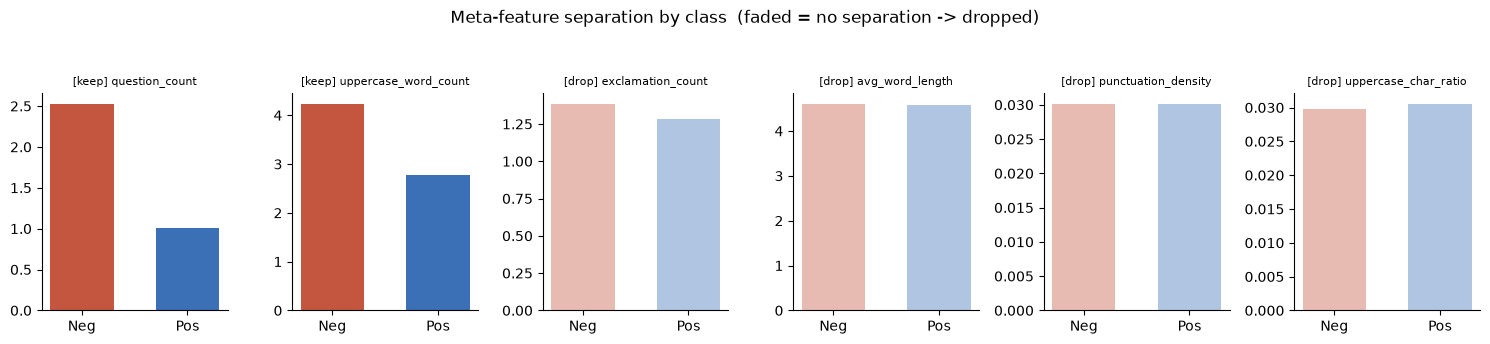

In [20]:
# ============================================================
# Step 7d — visualise: strong separators vs flat features
# ============================================================
NEG_COLOR, POS_COLOR = "#C4553E", "#3B6FB6"
show = ["question_count", "uppercase_word_count", "exclamation_count",
        "avg_word_length", "punctuation_density", "uppercase_char_ratio"]
fig, axes = plt.subplots(1, 6, figsize=(15, 3.2))
for ax, feat in zip(axes, show):
    means = df.groupby("sentiment")[feat].mean()
    keep = (means[0]/means[1] >= 1.15) or (means[0]/means[1] <= 0.87)
    ax.bar(["Neg", "Pos"], [means[0], means[1]],
           color=[NEG_COLOR, POS_COLOR], width=0.6, alpha=1.0 if keep else 0.4)
    ax.set_title(("[keep] " if keep else "[drop] ") + feat, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Meta-feature separation by class  (faded = no separation -> dropped)", y=1.06)
plt.tight_layout(); plt.show()


In [21]:
# ============================================================
# Step 7e - lock in the meta-features, DERIVED from the screening result
# ============================================================
# The keep/drop split is taken straight from the "separates?" column computed in
# Step 7c, so the decision cannot drift away from the evidence that produced it.
KEEP_META = by_class.index[by_class["separates?"] == "KEEP"].tolist()
DROP_META = by_class.index[by_class["separates?"] != "KEEP"].tolist()

print(f"Threshold applied: ratio >= 1.15 or <= 0.87 (a 15% difference either way)\n")
print(f"KEEPING ({len(KEEP_META)}):")
for f in KEEP_META:
    print(f"    {f:<22} ratio {by_class.loc[f, 'ratio neg/pos']:.2f}")
print(f"DROPPING ({len(DROP_META)}):")
for f in DROP_META:
    print(f"    {f:<22} ratio {by_class.loc[f, 'ratio neg/pos']:.2f}")

df = df.drop(columns=DROP_META)
print(f"\nRemaining meta-feature columns: {KEEP_META}")


Threshold applied: ratio >= 1.15 or <= 0.87 (a 15% difference either way)

KEEPING (2):
    question_count         ratio 2.52
    uppercase_word_count   ratio 1.53
DROPPING (4):
    exclamation_count      ratio 1.08
    uppercase_char_ratio   ratio 0.97
    punctuation_density    ratio 1.00
    avg_word_length        ratio 1.01

Remaining meta-feature columns: ['question_count', 'uppercase_word_count']


**Result: 2 of 6 kept.**

| Feature | Neg / pos ratio | Decision |
|---|---|---|
| `question_count` | 2.52 | **Keep** — negative reviews ask ~2.5× more questions (*"what were they thinking?"*) |
| `uppercase_word_count` | 1.53 | **Keep** — more shouting |
| `exclamation_count` | 1.08 | Drop — leans the expected way but is under the threshold; the rule was applied, not relaxed |
| `avg_word_length`, `punctuation_density`, `uppercase_char_ratio` | ~1.0 | Drop |

*Limitation:* comparing averages misses signal hidden in variance or interactions. Notebook 3 tests whether
the two kept features actually help the model.

## 11. Step 9 — Does the sentiment signal survive cleaning?

If the cleaning worked, positive and negative reviews should now use clearly different vocabulary, made of
sentiment words rather than names.

In [22]:
# ============================================================
# Step 8a — tokens MOST distinctive to each class (log-frequency ratio)
# ============================================================
pos_counts, neg_counts = collections.Counter(), collections.Counter()
for toks in df.loc[df.sentiment == 1, "clean_tokens"]: pos_counts.update(toks)
for toks in df.loc[df.sentiment == 0, "clean_tokens"]: neg_counts.update(toks)
pos_total, neg_total = sum(pos_counts.values()), sum(neg_counts.values())

# Two guards on which tokens qualify for the ranking:
#   1. total frequency >= 40, so the ratio is not driven by a handful of mentions
#   2. appears in >= 40 distinct shows, so it is GENERAL vocabulary rather than a
#      show-specific term. Without guard 2 the ranking fills up with any remaining
#      proper noun, because a name used only in one well-liked show has almost no
#      occurrences in the negative class and so scores an extreme positive ratio.
MIN_SHOWS_FOR_RANK = 40
vocab = {w for w in (pos_counts | neg_counts)
         if pos_counts[w] + neg_counts[w] >= 40
         and len(token_showcount.get(w, ())) >= MIN_SHOWS_FOR_RANK}
rows = []
for w in vocab:
    p = pos_counts[w] / pos_total + 1e-9
    n = neg_counts[w] / neg_total + 1e-9
    rows.append((w, np.log(p / n)))
ranked = pd.DataFrame(rows, columns=["token", "log_ratio"]).sort_values("log_ratio")
print(f"Ranking {len(vocab):,} general-vocabulary tokens "
      f"(freq >= 40 and present in >= {MIN_SHOWS_FOR_RANK} shows)\n")

print("Most NEGATIVE-leaning tokens:")
print(ranked.head(15).to_string(index=False))
print("\nMost POSITIVE-leaning tokens:")
print(ranked.tail(15).iloc[::-1].to_string(index=False))


Ranking 4,597 general-vocabulary tokens (freq >= 40 and present in >= 40 shows)

Most NEGATIVE-leaning tokens:
       token  log_ratio
    soulless  -3.221343
     unfunny  -3.099763
     abysmal  -2.888419
   laughably  -2.714953
   miserably  -2.564626
   atrocious  -2.506843
  horrendous  -2.455663
    pathetic  -2.402996
    dreadful  -2.347479
    offender  -2.347335
     garbage  -2.319703
insufferable  -2.286368
       appal  -2.261445
         stu  -2.243892
        slog  -2.240392

Most POSITIVE-leaning tokens:
         token  log_ratio
         fence   9.757979
   intricately   9.757979
    flawlessly   3.350203
       sublime   2.902645
      splendid   2.870290
       enjoyed   2.746240
           mob   2.496498
    delightful   2.340928
     orchestra   2.287511
       samurai   2.254148
    impeccable   2.177304
unconventional   2.177304
      blessing   2.090162
       diamond   2.084396
      terrific   2.071814


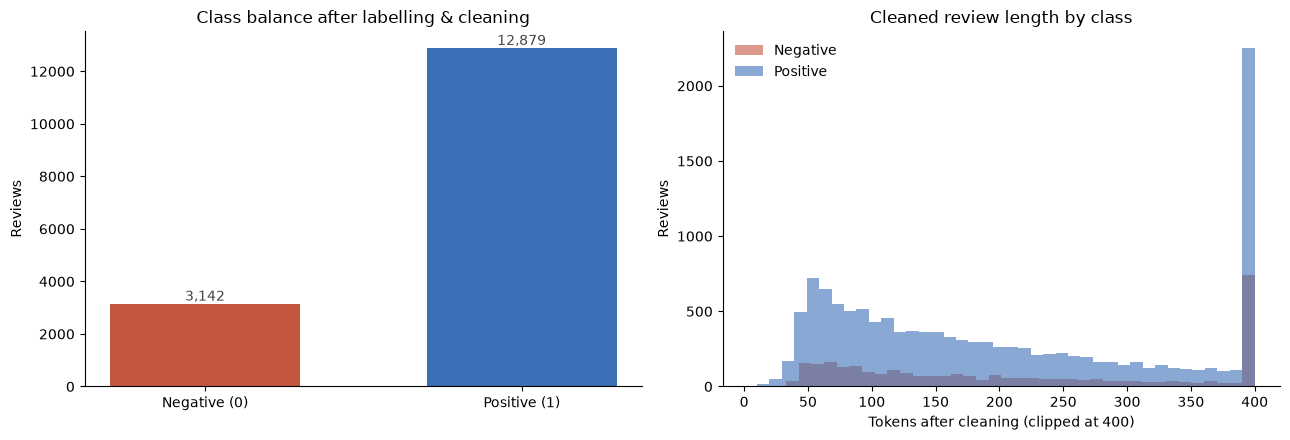

In [23]:
# ============================================================
# Step 8b — class balance & cleaned length by sentiment
# ============================================================
NEG_COLOR, POS_COLOR = "#C4553E", "#3B6FB6"
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

counts = df["sentiment"].value_counts().sort_index()
bars = axes[0].bar(["Negative (0)", "Positive (1)"], counts.values,
                   color=[NEG_COLOR, POS_COLOR], width=0.6)
for b in bars:
    axes[0].annotate(f"{int(b.get_height()):,}",
                     (b.get_x()+b.get_width()/2, b.get_height()),
                     ha="center", va="bottom", fontsize=10, color="#444")
axes[0].set_title("Class balance after labelling & cleaning")
axes[0].set_ylabel("Reviews")
axes[0].spines[["top", "right"]].set_visible(False)

for lbl, c, name in [(0, NEG_COLOR, "Negative"), (1, POS_COLOR, "Positive")]:
    axes[1].hist(df.loc[df.sentiment == lbl, "clean_word_count"].clip(upper=400),
                 bins=40, alpha=0.6, color=c, label=name)
axes[1].set_title("Cleaned review length by class")
axes[1].set_xlabel("Tokens after cleaning (clipped at 400)")
axes[1].set_ylabel("Reviews")
axes[1].legend(frameon=False)
axes[1].spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()


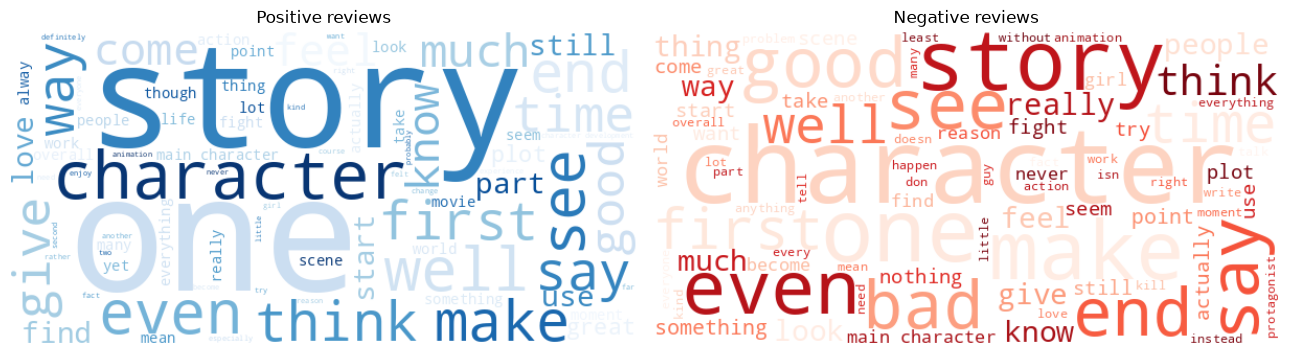

In [24]:
# ============================================================
# Step 8c — word clouds per class (visual sanity check)
# ============================================================
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, lbl, title, cmap in [(axes[0], 1, "Positive reviews", "Blues"),
                             (axes[1], 0, "Negative reviews", "Reds")]:
    text = " ".join(df.loc[df.sentiment == lbl, "clean_text"])
    wc = WordCloud(width=600, height=300, background_color="white",
                   colormap=cmap, max_words=80).generate(text)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(title)
plt.tight_layout(); plt.show()


**Insight.** The most negative-leaning words are *soulless, unfunny, abysmal, atrocious, pathetic* —
vocabulary any reviewer of any show could use, which is exactly what context blindness needs.

*A metric that needed a guard:* before requiring a word to appear in ≥ 40 shows, the positive end of this
ranking filled up with leftover character names. A name from one well-liked show occurs almost only in
positive reviews, so its ratio is extreme even though it says nothing transferable.

## 12. Step 10 — Save

`Dataset_A_clean.csv` keeps the raw text (for error analysis) next to the cleaned text, the kept features
and the label. `clean_artifacts.json` freezes the stop-words, the strip-set and the kept features.

In [25]:
# ============================================================
# Step 9 - write Dataset_A_clean.csv
# ============================================================
# meta-feature columns come from KEEP_META, so the file matches the screening result
out_cols = (["anime_id", "anime_title", "rating", "sentiment", "tag",
             "raw_word_count", "clean_word_count", "unique_word_count"]
            + KEEP_META
            + ["review_text", "clean_text"])
clean_df = df[out_cols].copy()

clean_df.to_csv(CLEAN_A_PATH, index=False, encoding="utf-8-sig")
print(f"Saved: {CLEAN_A_PATH}")
print(f"Rows: {len(clean_df):,} | Columns: {len(out_cols)}")
print(f"Meta-features kept: {KEEP_META}")

# Persist the cleaning artifacts so the modelling notebook can clean the held-out
# Dataset B with the IDENTICAL frozen logic (same stop-words, same entity strip-set,
# same surviving meta-features).
import json
artifacts = {
    "stopwords":  sorted(STOPWORDS),
    "strip_set":  sorted(STRIP_SET),
    "keep_meta":  KEEP_META,
    "freq_min":   FREQ_MIN,
    "shows_max":  SHOWS_MAX,
}
ART_PATH = os.path.join(DATA_DIR, "clean_artifacts.json")
with open(ART_PATH, "w", encoding="utf-8") as f:
    json.dump(artifacts, f)
print(f"Saved cleaning artifacts: {ART_PATH} "
      f"({len(artifacts['stopwords'])} stop-words, {len(artifacts['strip_set'])} strip tokens, "
      f"{len(KEEP_META)} meta-features)")
print(f"\nFinal class balance -> "
      f"negative {(clean_df.sentiment==0).mean()*100:.1f}% | "
      f"positive {(clean_df.sentiment==1).mean()*100:.1f}%")
clean_df[["anime_title", "rating", "sentiment", "clean_word_count", "clean_text"]].head(3)


Saved: data\Dataset_A_clean.csv
Rows: 16,021 | Columns: 12
Meta-features kept: ['question_count', 'uppercase_word_count']
Saved cleaning artifacts: data\clean_artifacts.json (202 stop-words, 2427 strip tokens, 2 meta-features)

Final class balance -> negative 19.6% | positive 80.4%


,anime_title,rating,sentiment,clean_word_count,clean_text
0,Shingeki no Kyojin,10,1,489,dear even begin talk friend couple everyone ta...
1,Shingeki no Kyojin,10,1,240,start follow quite frankly don see plot suck h...
2,Shingeki no Kyojin,10,1,567,mobile suit gundam catapult japan dragon ball ...


## 13. Summary

| Step | Outcome |
|---|---|
| Dedupe + label | 16,021 reviews, neutral 5–6 band dropped |
| Text cleaning | POS-aware lemmatisation, negations kept, domain filler removed |
| Name removal | 2,427 tokens stripped by a statistical rule, verified against an external lexicon |
| Features | 2 of 6 style features kept |
| Output | `Dataset_A_clean.csv` + `clean_artifacts.json` |

**Carried into notebook 3:** the 4 : 1 imbalance (macro-F1, stratified splits, class weights); Dataset B must
be cleaned with the frozen artifacts; a few famous names survive, so the held-out Dataset B score is the real
test of generalisation.

**Next:** `03_Modelling.ipynb`